In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns              #Libreria de visualizacion de alto nivel

In [ ]:
!pip install seaborn

In [2]:
path="../data/Obesidad_Infantil.csv"
encoding = "latin1"
df= pd.read_csv(path, encoding=encoding)

In [3]:
df.columns

Index(['PESO (KG)', 'TALLA (MT)', 'CIRCUNFERENCIA DE CINTURA', 'EDAD',
       'ÍNDICE CINTURA/TALLA', 'IMC', 'SEXO'],
      dtype='object')

<Axes: xlabel='EDAD,SEXO'>

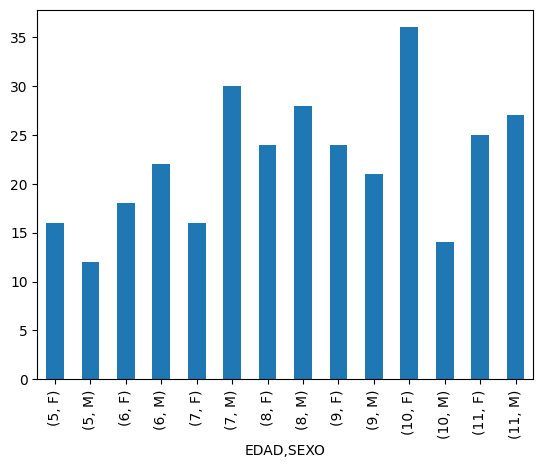

In [4]:
edad_sexo= df[["EDAD","SEXO"]].value_counts().sort_index()
edad_sexo         #tabla de frecuencias bivariable
edad_sexo.plot(kind="bar")   #devuelve un grafico de barras bivariable

In [15]:
df.value_counts(
    subset=["EDAD","SEXO"]
).sort_index()

EDAD  SEXO
5     F       16
      M       12
6     F       18
      M       22
7     F       16
      M       30
8     F       24
      M       28
9     F       24
      M       21
10    F       36
      M       14
11    F       25
      M       27
dtype: int64

<Axes: xlabel='EDAD', ylabel='Porcentaje'>

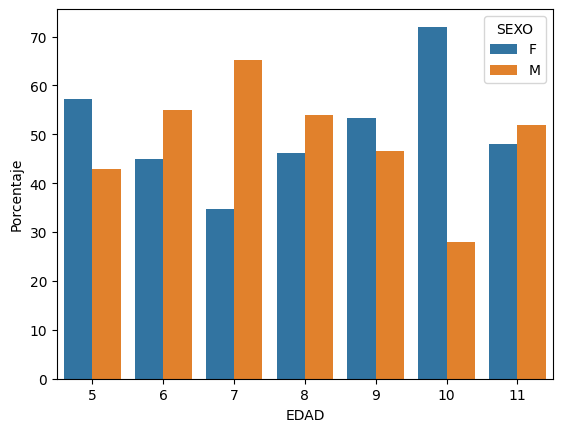

In [56]:
tab_porc= (df.groupby("EDAD")["SEXO"]
           .value_counts(normalize=True)
           .mul(100)
           .rename("Porcentaje")
           .reset_index())
sns.barplot(data=tab_porc, x="EDAD", y= "Porcentaje", hue="SEXO")

In [46]:
cont=pd.crosstab(df["SEXO"],df["EDAD"])
type(cont)

pandas.core.frame.DataFrame

<Axes: xlabel='EDAD', ylabel='SEXO'>

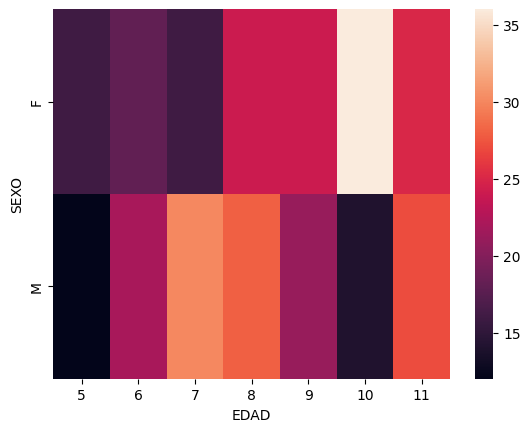

In [47]:
sns.heatmap(cont)

<Axes: ylabel='Frequency'>

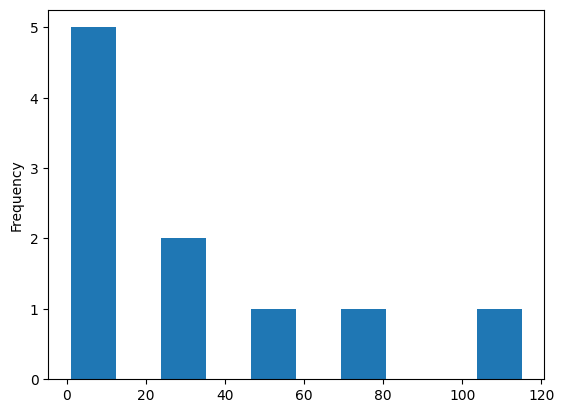

In [7]:
imc= pd.cut(df["IMC"],bins=10)
imc.value_counts().sort_index().plot(kind="hist")



<Axes: xlabel='EDAD', ylabel='count'>

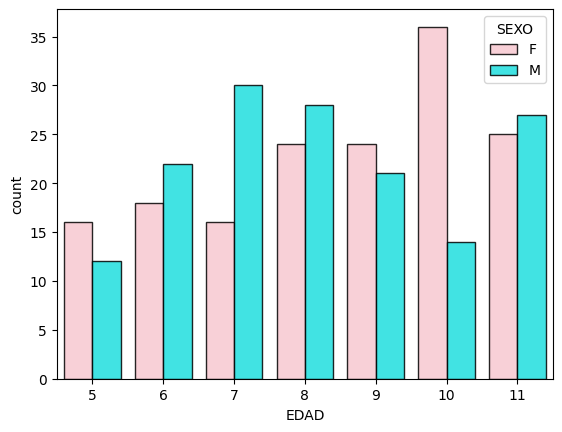

In [8]:
paleta = ["pink", "cyan"]
paleta={"F":"pink","M":"cyan"}
sns.countplot(data=df, x="EDAD", hue="SEXO", palette=paleta, edgecolor="black", alpha=0.85)
#palette puede recibir listas y diccionarios
#countplot() devuelve un grafico de barras, y con hue lo devuelve bivariado


<Axes: xlabel='EDAD', ylabel='count'>

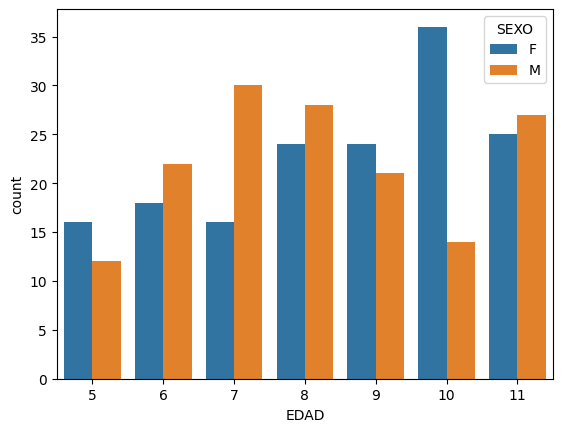

In [8]:
sns.countplot(data=df, x="EDAD", hue="SEXO")

<Axes: xlabel='SEXO', ylabel='EDAD'>

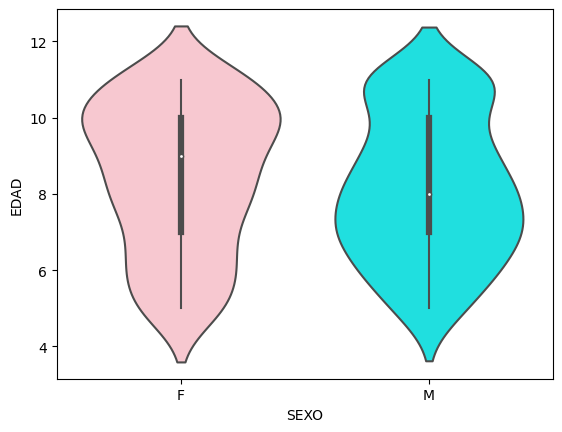

In [19]:
sns.violinplot(data=df, x="SEXO", y="EDAD", palette=paleta)

<Axes: xlabel='EDAD', ylabel='IMC'>

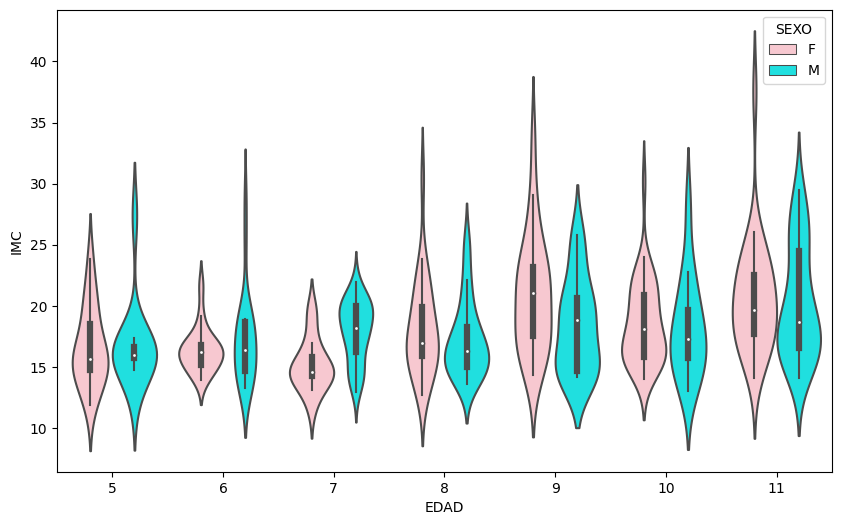

In [ ]:
plt.figure(figsize=(10,6))
#paleta=["pink","cyan"]
sns.violinplot(data=df, x="EDAD", y="IMC", palette=paleta, hue="SEXO")


<Axes: xlabel='SEXO', ylabel='EDAD'>

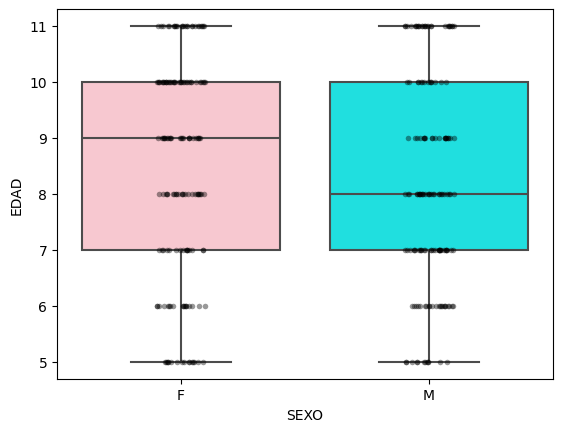

In [ ]:

sns.boxplot(data=df, x="SEXO", y="EDAD", palette=paleta)
sns.stripplot(data=df, x="SEXO", y="EDAD", color="black", alpha=0.4, size=4)

c:\Users\Ivan galeno reyes\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\categorical.py:3544: UserWarning: 6.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\Ivan galeno reyes\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\categorical.py:3544: UserWarning: 7.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\Ivan galeno reyes\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\categorical.py:3544: UserWarning: 8.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\Ivan galeno reyes\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\categorical.py:3544: UserWarning: 6.7% of the points cannot be placed; you may want to decrease the size of the 

<Figure size 1500x1000 with 0 Axes>

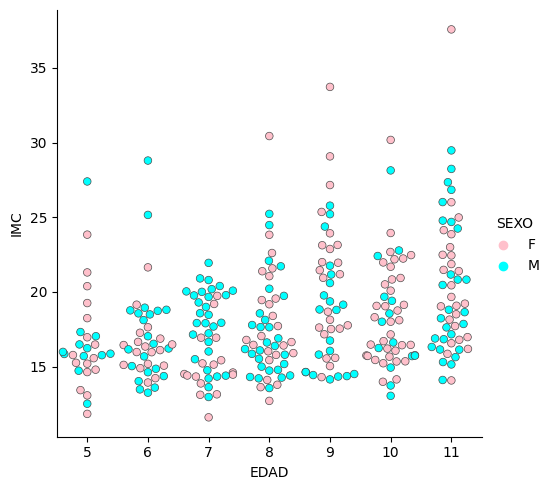

In [10]:
#Analisis multivariable incluyendo variables continuas 
plt.figure(figsize=(15,10))
sns.catplot(data=df, x="EDAD", y="IMC", kind="swarm", hue= "SEXO",palette=paleta, s=30, linewidth=0.5)